# NASA IMS Bearings — Early Warnings, Healthy-Bearing Checks & Feature Ablation

**Follow-up to:** `bearings_pipeline.ipynb` → `bearings_future_work.ipynb` → `bearings_improvement.ipynb`.

## Research questions
1. Does the tuned Extra Trees model warn before a known bearing failure? How many hours in advance?
2. Does it raise warnings on bearings **without a documented failure** in the same IMS experiment?
3. Do time-domain, spectrum, or characteristic fault-frequency features matter most?
4. Why is `3rd_test_b3` difficult near failure?

**Important:** These are retrospective held-out evaluations, not industrially validated failure alarms. All bearings in the same IMS test share a rig and environment. Non-failing bearings are *right-censored*, not confirmed healthy throughout their future lives.


## 1. Setup

Put this notebook and `bearings_diagnostics.py` beside your prior two scripts. You must have `bearings_out/features_raw.pkl`, `bearings_out/improvement/selected_configurations.csv`, and your extracted NASA dataset under `bearings/1st_test`, `bearings/2nd_test`, `bearings/3rd_test`.

The script **reuses** cached features for the four failed bearings and extracts only features of the eight other bearings. This first extraction reads the raw dataset once and caches it. Subsequent runs are faster.

Run the next cell and adjust paths if your folder differs.

In [12]:
%matplotlib inline

In [2]:
# %pip install numpy pandas scipy scikit-learn joblib matplotlib
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
import importlib
import bearings_diagnostics as bd
importlib.reload(bd)

DATA_ROOT = Path('bearings')
RAW_CACHE = Path('bearings_out/features_raw.pkl')
IMPROVEMENT = Path('bearings_out/extratrees')
OUT = Path('bearings_out/diagnostics')
N_JOBS = 4            # use 1 or 2 if RAM is limited
TREES = 500           # use 100 for quick dry run; 500 for final comparison
ABLATION_TREES = 250 # ablation is explanatory, not hyperparameter selection

for path in (DATA_ROOT,RAW_CACHE,IMPROVEMENT/'selected_configurations.csv'):
    print(path, 'exists:',path.exists())
assert RAW_CACHE.exists(), 'Run the old bearing feature extraction notebook first.'
assert (IMPROVEMENT/'selected_configurations.csv').exists(), 'Run bearings_improvement.ipynb first.'
assert DATA_ROOT.exists(), 'Set DATA_ROOT to extracted NASA IMS test folders.' 

bearings exists: True
bearings_out\features_raw.pkl exists: True
bearings_out\improvement\selected_configurations.csv exists: True


## 2. What will be evaluated?

For **each held-out test experiment**, the baseline and tuned models are fitted on the four *known failed-bearing trajectories from the other two experiments*. The tuned configuration is taken from your previous inner validation CSV; it is not chosen from these test outcomes. Predictions are generated for all four bearings in the held-out experiment.

Thresholds of **0.9, 0.8, 0.7**, and a persistence of **six consecutive snapshots**, are predetermined. A warning is counted only after the healthy-reference interval (70 operating hours). For a documented failure, lead time is the interval between the first confirmed warning and the known failure endpoint. For a non-failing bearing, any warning is counted as a warning on a *censored* trajectory (possibly transmitted vibration, not necessarily a false physical diagnosis).

In [3]:
raw = pd.read_pickle(RAW_CACHE)
print('Failed-bearing cache:',raw.shape)
display(raw.groupby(['test','bearing']).size().rename('snapshots').to_frame())
print('Previous selected configurations:')
display(pd.read_csv(IMPROVEMENT/'selected_configurations.csv'))

Failed-bearing cache: (8667, 33)


snapshots
test     bearing           
1st_test b3            2156
         b4            2156
2nd_test b1             984
3rd_test b3            3371

Previous selected configurations:


,outer_test,feature_set,leaf,max_features,late_weight,win,alpha
0,1st_test,base,20,0.5,2,15,0.2
1,2nd_test,base,20,0.5,2,15,0.2
2,3rd_test,history,75,0.3,3,10,0.2


## 3. Run all diagnostics

This can be computationally intensive on the first run because there are thousands of IMS vibration snapshots. Additional-bearing features are cached **by experiment** after extraction.

An experiment that has never been run on the dataset cannot be claimed as an improvement until its measured outputs are available.

In [4]:
results = bd.run_diagnostics(
    raw_fail=raw,
    data_root=DATA_ROOT,
    improvement_dir=IMPROVEMENT,
    out_dir=OUT,
    n_jobs=N_JOBS,
    trees=TREES,
    ablation_trees=ABLATION_TREES,
)

Extracting 1st_test: 2156 snapshots, bearings ['b1', 'b2']
Saved: bearings_out\diagnostics\raw_feature_cache\1st_test_additional_bearings.pkl
Extracting 2nd_test: 984 snapshots, bearings ['b2', 'b3', 'b4']
Saved: bearings_out\diagnostics\raw_feature_cache\2nd_test_additional_bearings.pkl
Extracting 3rd_test: 3371 snapshots, bearings ['b1', 'b2', 'b4']
Saved: bearings_out\diagnostics\raw_feature_cache\3rd_test_additional_bearings.pkl
Finished held-out experiment 1st_test
Finished held-out experiment 2nd_test
Finished held-out experiment 3rd_test
Finished ablations for 1st_test
Finished ablations for 2nd_test
Finished ablations for 3rd_test

ALERT SUMMARY
               model  threshold  documented_failure  n_bearings  n_bearings_alerted  mean_lead_hours  fraction_bearings_alerted
ExtraTrees_baseline        0.7               False           8                   2              NaN                      0.250
ExtraTrees_baseline        0.7                True           4                   3 

## 4. Early warning / alarm results

Rows with `documented_failure=False` are **censored observations**, not certain true negatives. Avoid calling this an estimated population-level specificity.

In [5]:
display(results['alert_summary'].round(3))
view = results['alerts'].query('threshold == 0.9')
display(view[['run','model','documented_failure','alerted','first_alert_hours','lead_hours_if_failed','alerts']].round(2))

,model,threshold,documented_failure,n_bearings,n_bearings_alerted,mean_lead_hours,fraction_bearings_alerted
0,ExtraTrees_baseline,0.7,False,8,2,NaN,0.250
1,ExtraTrees_baseline,0.7,True,4,3,42.966,0.750
2,ExtraTrees_baseline,0.8,False,8,3,NaN,0.375
3,ExtraTrees_baseline,0.8,True,4,3,55.426,0.750
4,ExtraTrees_baseline,0.9,False,8,6,NaN,0.750
5,ExtraTrees_baseline,0.9,True,4,3,70.081,0.750
6,ExtraTrees_tuned,0.7,False,8,3,NaN,0.375
7,ExtraTrees_tuned,0.7,True,4,3,48.911,0.750
8,ExtraTrees_tuned,0.8,False,8,5,NaN,0.625
9,ExtraTrees_tuned,0.8,True,4,3,58.865,0.750


,run,model,documented_failure,alerted,first_alert_hours,lead_hours_if_failed,alerts
0,1st_test_b1,ExtraTrees_baseline,False,True,86.36,NaN,1
3,1st_test_b1,ExtraTrees_tuned,False,True,85.03,NaN,1
6,1st_test_b2,ExtraTrees_baseline,False,True,344.32,NaN,1
9,1st_test_b2,ExtraTrees_tuned,False,True,342.99,NaN,1
12,1st_test_b3,ExtraTrees_baseline,True,True,298.28,46.99,1
15,1st_test_b3,ExtraTrees_tuned,True,True,306.11,39.16,1
18,1st_test_b4,ExtraTrees_baseline,True,True,250.68,94.59,1
21,1st_test_b4,ExtraTrees_tuned,True,True,251.93,93.34,1
24,2nd_test_b1,ExtraTrees_baseline,True,True,95.17,68.67,1
27,2nd_test_b1,ExtraTrees_tuned,True,True,92.50,71.33,1


## 5. Compare trajectories for all four bearings in each experiment

A dashed vertical line marks the **first sustained tuned-model warning**. Neither onset nor reference labels are needed for generating these alerts.

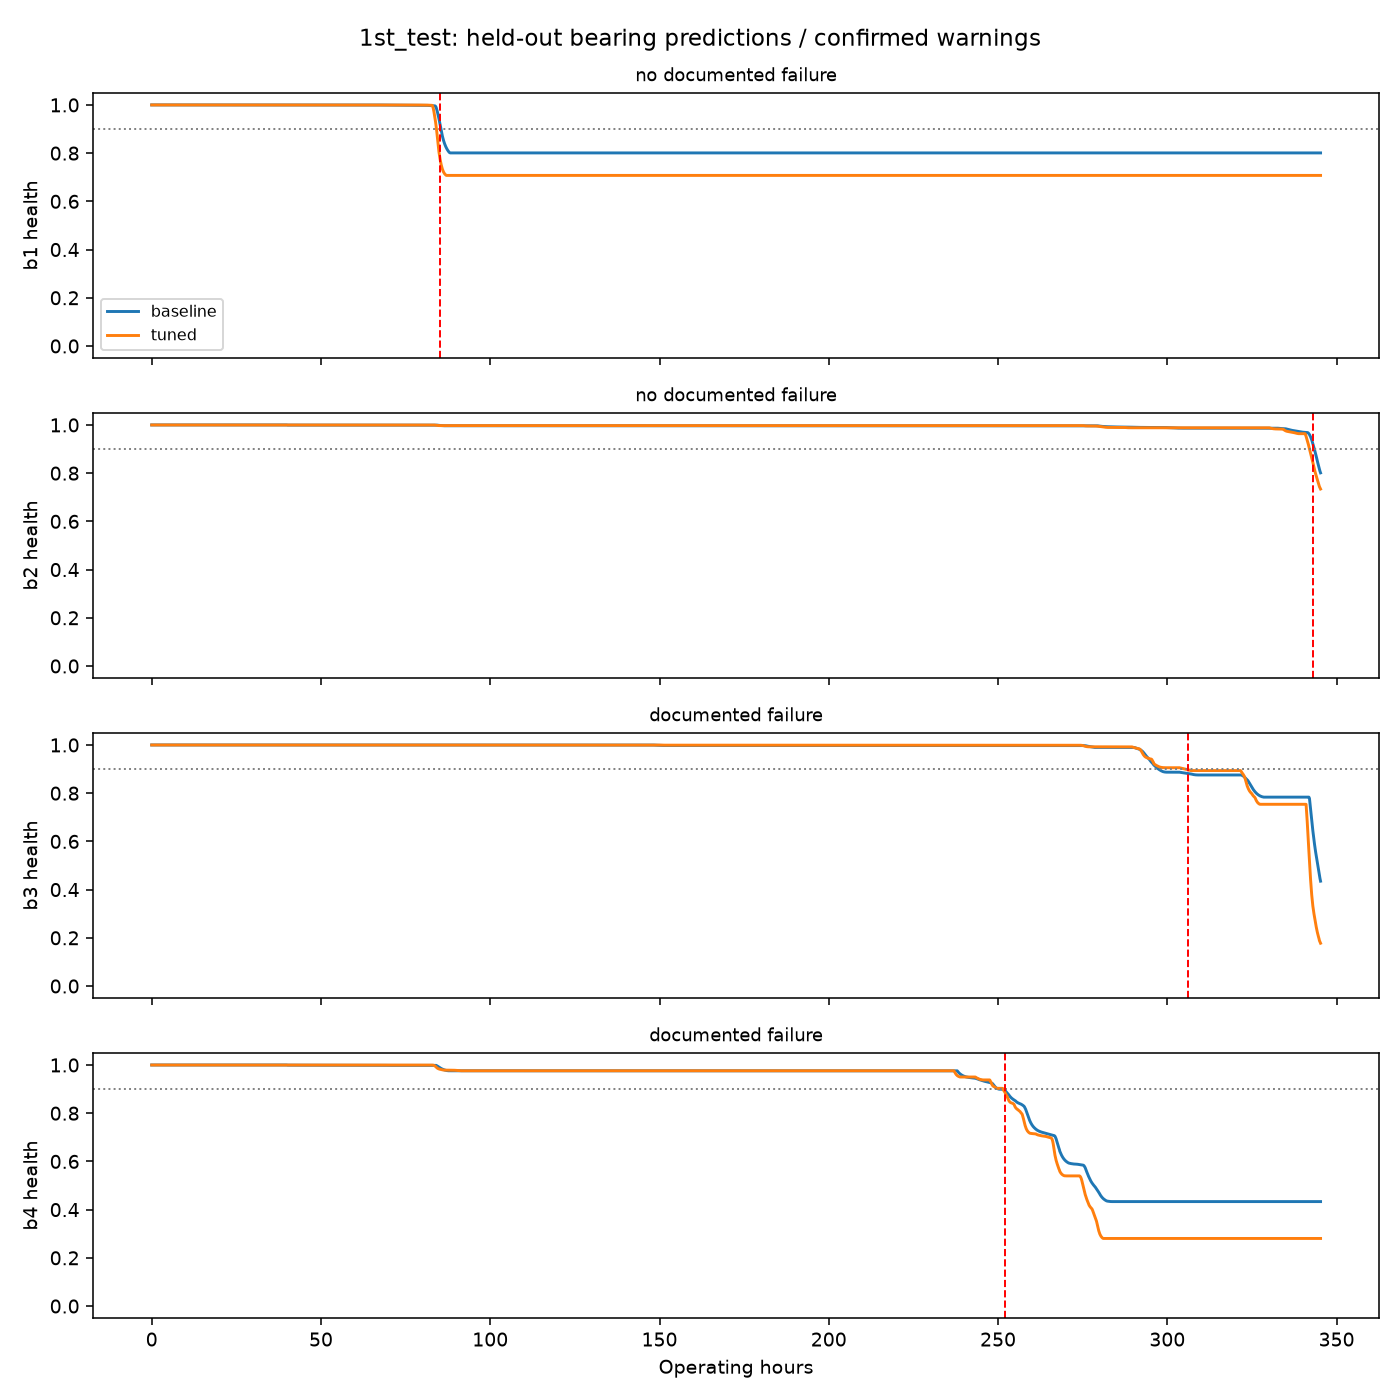

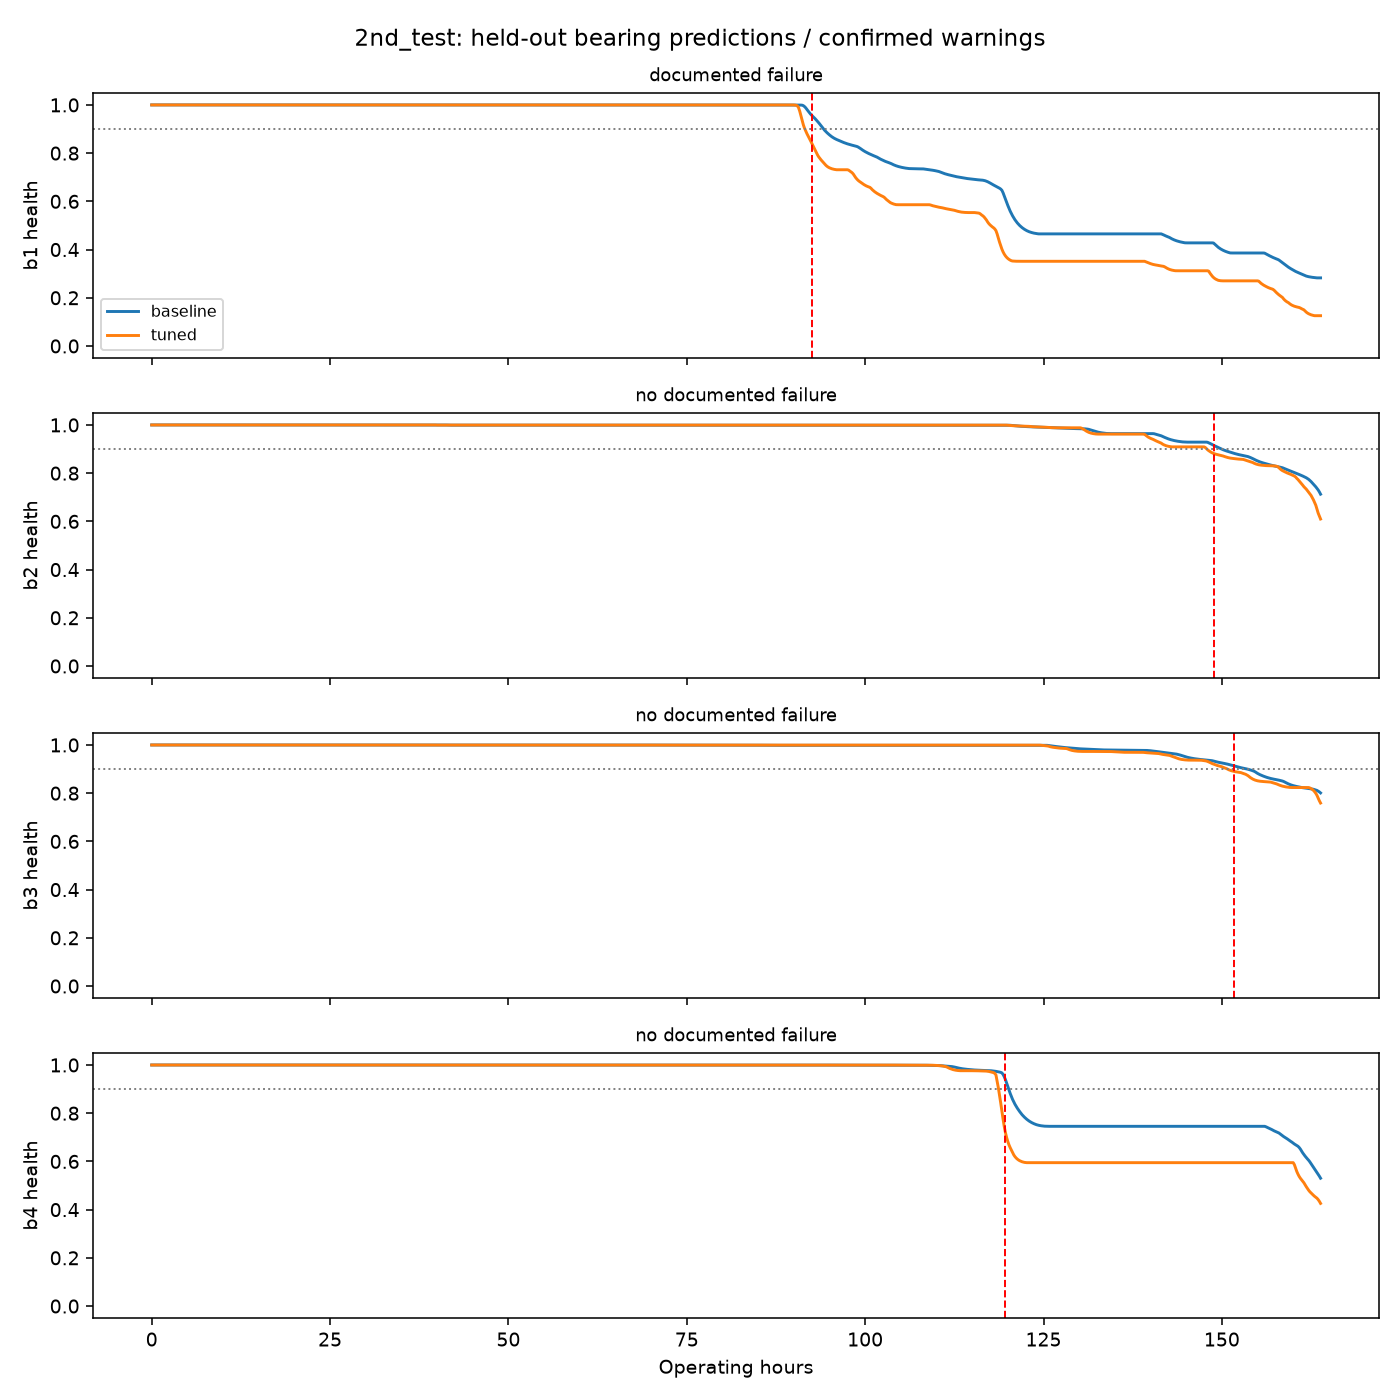

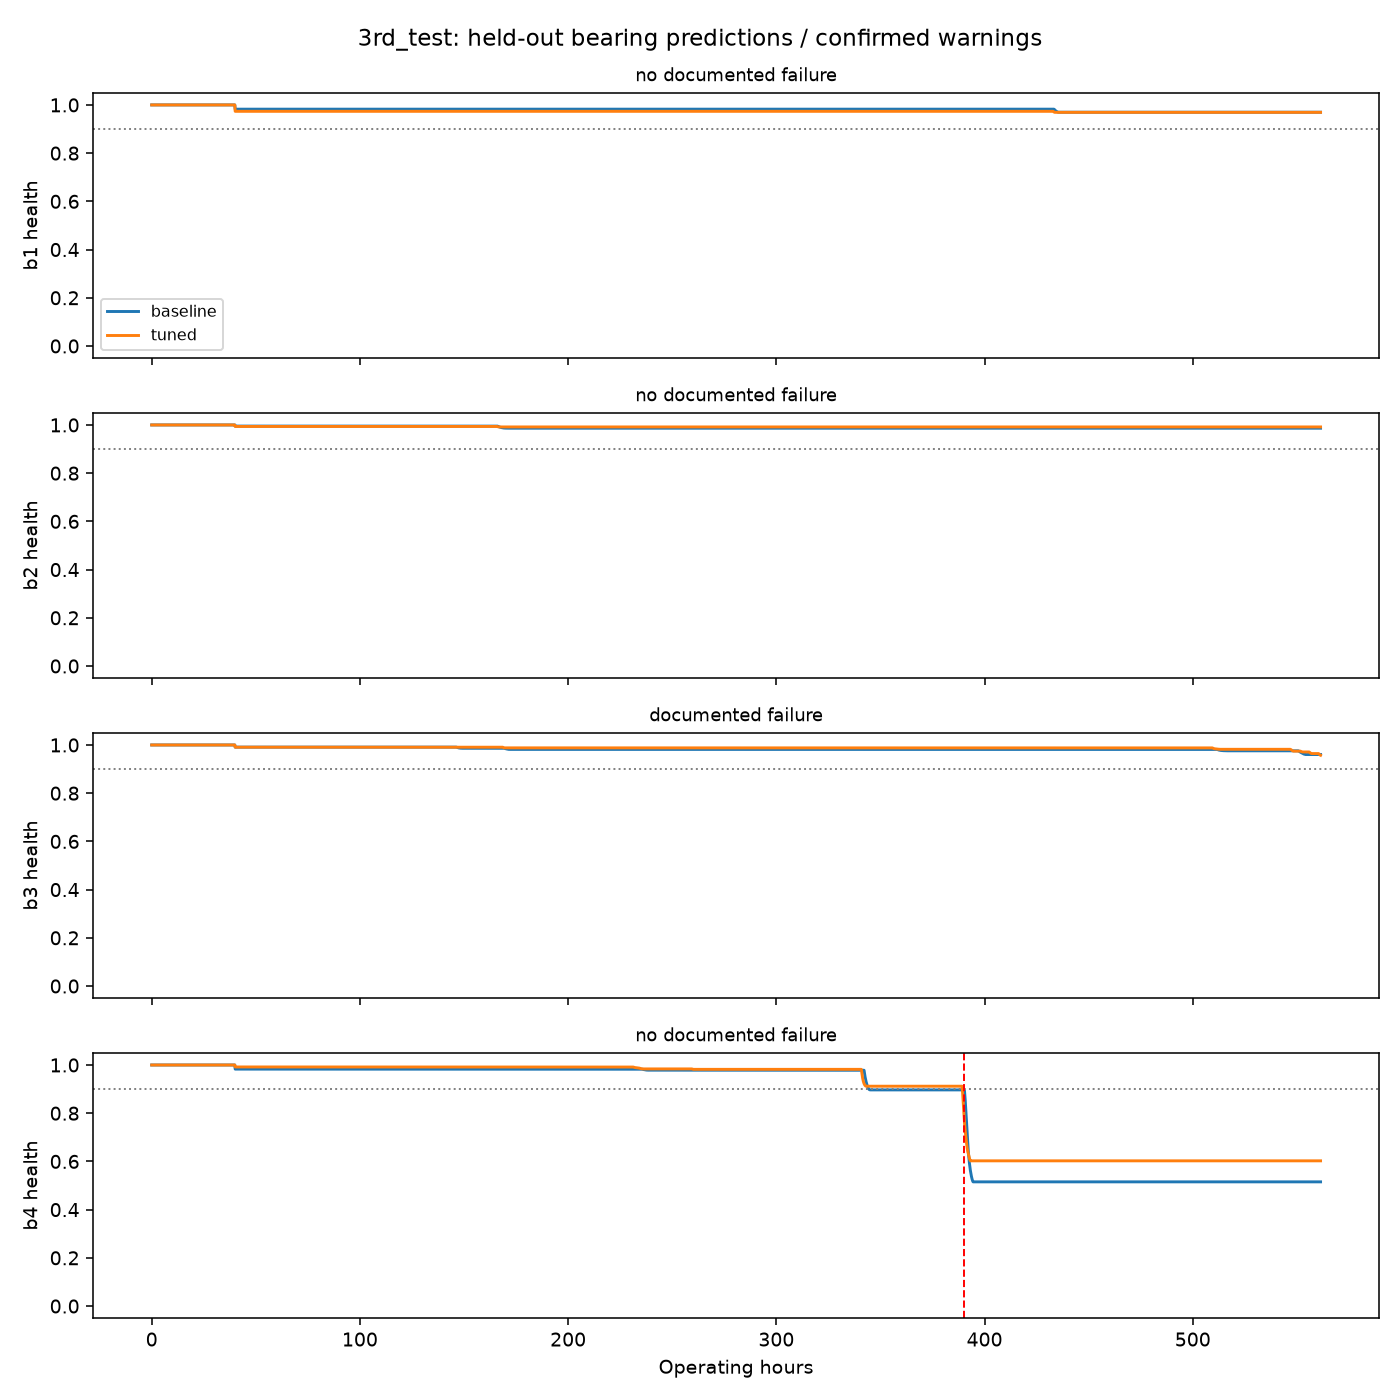

In [6]:
for test in bd.CHANNELS:
    path = OUT / f'{test}_all_bearings.png'
    display(Image(filename=str(path)))

## 6. Ablation: which feature families help?

The *52-feature* baseline is split into time-domain, spectral, and fault-frequency families, including their lagged slopes. We retrain models keeping only or excluding these families; the outer test runs are not used to choose the model settings. This experiment explains feature dependence, but does not prove a unique causal contribution (feature groups are correlated).

,RMSE,RMSE_late,late_overestimate_mean
variant,,,
only_fault_frequency,0.1159,0.2962,0.2484
without_spectrum,0.1122,0.3323,0.3085
only_spectrum,0.1407,0.3410,0.3038
without_time_domain,0.1313,0.3480,0.3100
all_52,0.1340,0.3552,0.3200
without_fault_frequency,0.1391,0.3731,0.3362
only_time_domain,0.1606,0.4107,0.3633


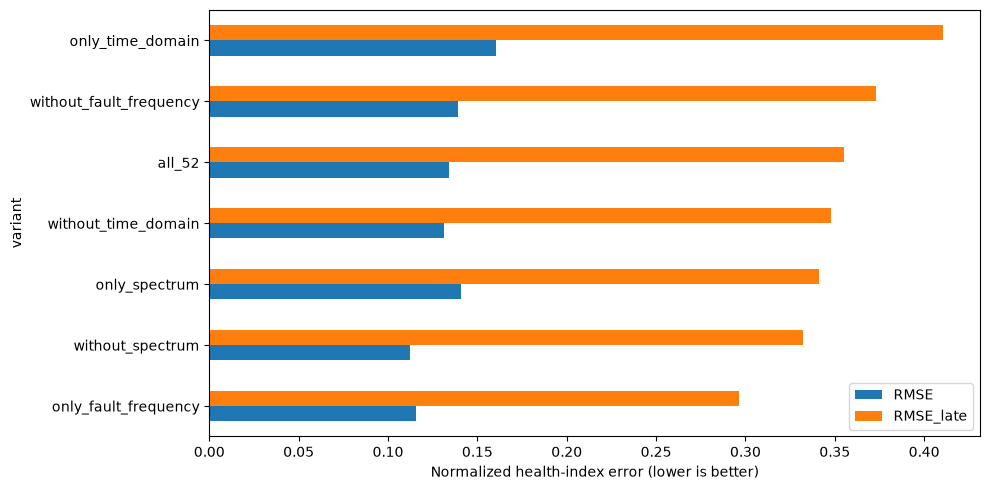

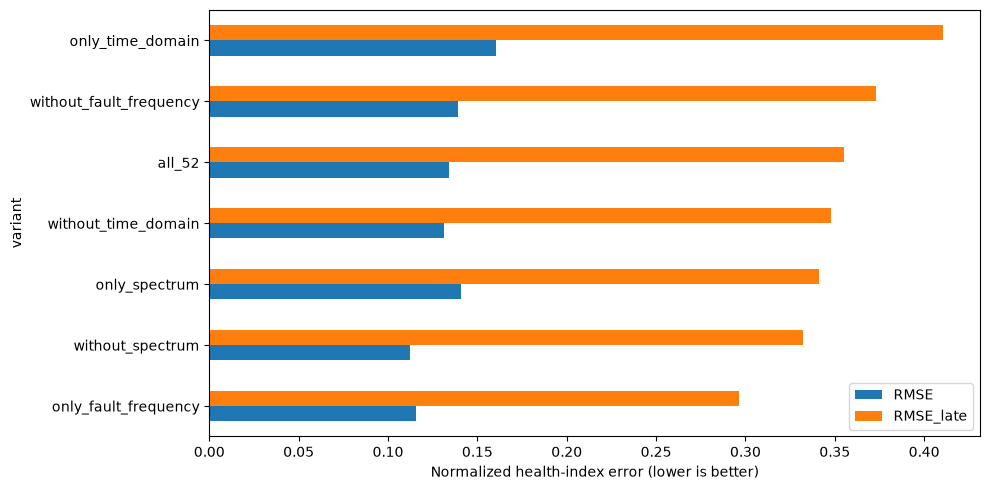

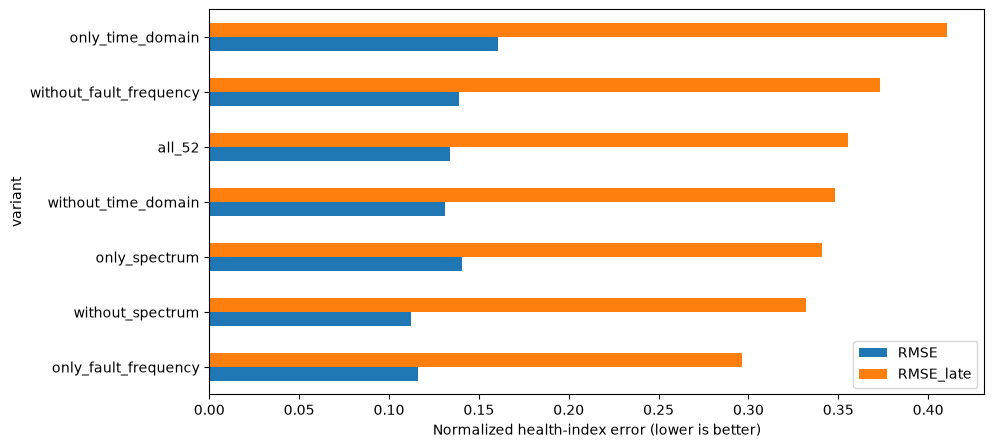

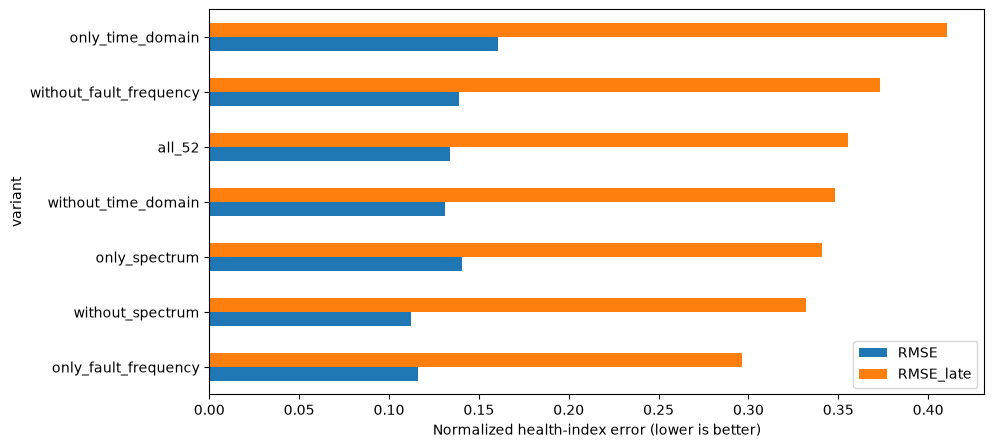

In [13]:
display(results['ablation_summary'].sort_values('RMSE_late').round(4))
ax=results['ablation_summary'][['RMSE','RMSE_late']].sort_values('RMSE_late').plot(kind='barh',figsize=(10,5))
ax.set_xlabel('Normalized health-index error (lower is better)')
# plt.tight_layout()
plt.show()

## 7. Investigate `3rd_test_b3`

This diagnostic graph shows normalized RMS, kurtosis, and characteristic envelope frequencies alongside the cross-fitted predictions. If the features rise only in the final moments, the model may have little useful lead time; it is not enough to assert a particular fault mechanism without physical confirmation.

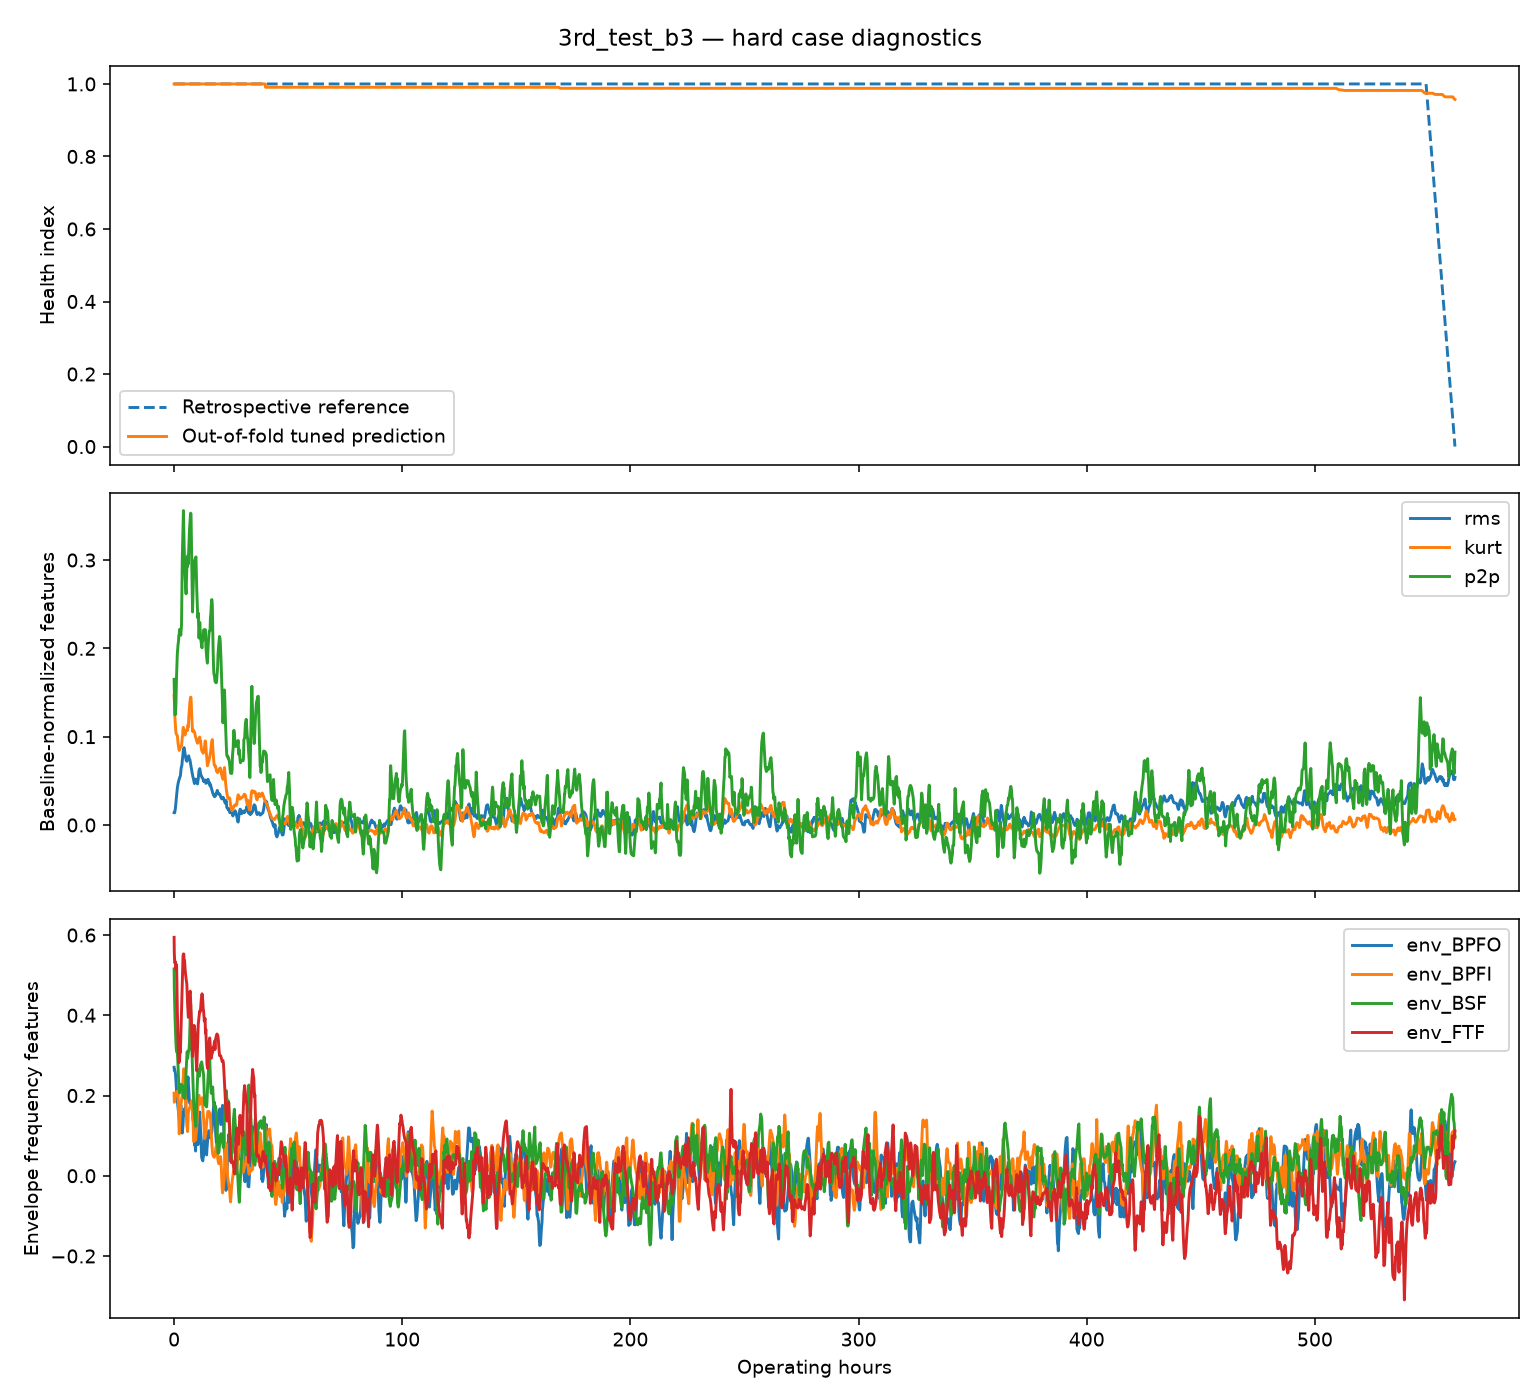

In [8]:
display(Image(filename=str(OUT/'hard_bearing_diagnostics.png')))

## 8. Summarize for your final presentation

Suggested honest conclusions after inspecting your outputs:

- Report sustained-warning lead time separately for each documented failure and each threshold.
- Report the proportion of **non-failed/censored bearings with warnings**; do not equate that directly to verified false diagnoses.
- Use ablation errors to identify which feature families appear useful or redundant.
- Discuss the trade-off between earlier warnings, warning frequency, and RMSE.
- **Never select thresholds or hyperparameters based on these outer test results and call the same results unbiased.** Further optimization requires new independent held-out data or properly nested validation.

All numerical claims should come from the CSV outputs, not expectations.

In [9]:
print('Files generated:')
for p in sorted(OUT.glob('*')):
    if p.is_file(): print('-',p.name)

# Easy-to-export tables for your report
results['alert_summary'].to_csv(OUT/'report_alert_table.csv', index=False)
results['ablation_summary'].to_csv(OUT/'report_ablation_table.csv')

Files generated:
- 1st_test_all_bearings.png
- 2nd_test_all_bearings.png
- 3rd_test_all_bearings.png
- alert_evaluation.csv
- alert_summary.csv
- all_bearing_predictions.csv
- feature_ablation_per_run.csv
- feature_ablation_summary.csv
- hard_bearing_diagnostics.png
- READ_ME.txt
